# M5: City segments and KPIs

This is the Path B follow-up to the M4 notebook. It looks at where connection-seeking posts are concentrated, when they are posted, and which age groups post which kind of intent. The window is still Aug 2025 to Aug 2026.

In [1]:
import os

import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv("../data/processed/posts_clean.csv", low_memory=False)
df["date_manila"] = pd.to_datetime(df["date_manila"])
window = df[df["date_manila"] >= "2025-08-01"].copy()

pop = pd.read_csv("../data/reference/metro_manila_population.csv")
pop_lookup = dict(zip(pop["city"], pop["population"]))

window["late_night"] = window["hour_manila"].isin([22, 23, 0, 1])
os.makedirs("../output/tables", exist_ok=True)

print(len(window), "posts from", window["date_manila"].min().date(), "to", window["date_manila"].max().date())


197082 posts from 2025-08-01 to 2026-08-03


## What I compare

| Segment | Why it matters | Metric |
|---|---|---|
| City | Where the demand is | posts per 100k, late-night share, subreddit rates |
| Age band | Who is posting | intent mix |
| Month | Whether the pattern is stable | posts per day, late-night share |

I use four KPIs: posts per 100,000 residents, late-night share (10 PM to 2 AM), platonic posts per 100,000, and sexual posts per 100,000. The first two are for reach and scheduling; the last two compare friendship and sexual-health demand without pooling the subreddits into one share.


I keep the city, age, and month views separate so each one answers a different question. For cities, I compare per-100k rates instead of pooled shares so the subreddit mix does not mechanically change the number.


In [2]:
city_posts = window[window["city"].isin(pop_lookup)].pivot_table(
    index="city", columns="category", values="post_id", aggfunc="count"
).fillna(0)

kpi = pd.DataFrame(index=city_posts.index)
kpi["posts"] = city_posts.sum(axis=1)
kpi["population"] = kpi.index.map(pop_lookup)
kpi["posts_per_100k"] = kpi["posts"] / kpi["population"] * 100_000
kpi["general_per_100k"] = city_posts["all"] / kpi["population"] * 100_000
for cat in ["platonic", "romantic", "sexual"]:
    kpi[cat + "_per_100k"] = city_posts[cat] / kpi["population"] * 100_000

late = window[window["city"].isin(pop_lookup)].groupby("city")["late_night"].mean()
kpi["late_night_share"] = late
kpi = kpi.sort_values("posts_per_100k", ascending=False)

show = kpi.head(10).copy()
show["late_night_share"] = (show["late_night_share"] * 100).round(1)
show.round(1)


,posts,population,posts_per_100k,general_per_100k,platonic_per_100k,romantic_per_100k,sexual_per_100k,late_night_share
city,,,,,,,,
Makati,8965.0,309770,2894.1,1905.3,464.2,124.6,400.0,19.6
Manila,14199.0,1902590,746.3,450.2,104.9,31.1,160.2,24.9
Quezon City,18287.0,3084270,592.9,360.5,65.4,25.0,142.0,22.2
Mandaluyong,2244.0,465902,481.6,343.2,36.7,11.2,90.6,24.2
Taguig,5918.0,1308085,452.4,261.3,76.4,18.7,96.0,20.8
Pasay,1942.0,453186,428.5,231.9,30.7,11.0,154.9,24.9
Pasig,3238.0,853050,379.6,256.1,35.4,14.7,73.4,26.5
Marikina,1645.0,471323,349.0,248.7,43.5,12.1,44.8,22.5
San Juan,416.0,134312,309.7,209.2,35.0,14.1,51.4,23.6


Makati leads every per-100k rate, while Pasay and Manila are close on late-night share. Pasay and Manila both have plenty of nightlife options.


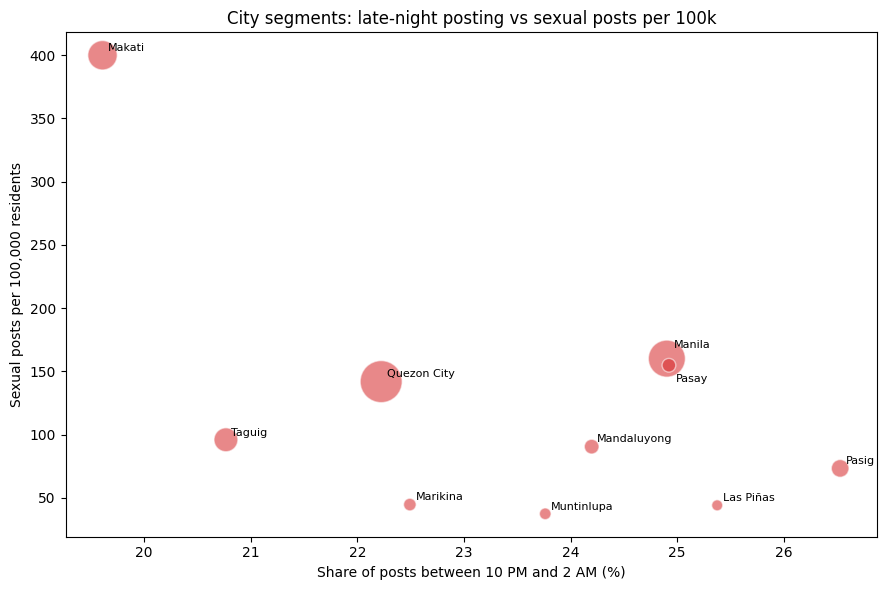

In [3]:
top = kpi[kpi["posts"] >= 1000]
offsets = {"Manila": (5, 8), "Pasay": (5, -12)}

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(
    top["late_night_share"] * 100,
    top["sexual_per_100k"],
    s=top["posts"] / 20,
    alpha=0.55,
    color="tab:red",
    edgecolor="white",
)
for city, row in top.iterrows():
    ax.annotate(
        city,
        (row["late_night_share"] * 100, row["sexual_per_100k"]),
        xytext=offsets.get(city, (4, 3)),
        textcoords="offset points",
        fontsize=8,
    )
ax.set_title("City segments: late-night posting vs sexual posts per 100k")
ax.set_xlabel("Share of posts between 10 PM and 2 AM (%)")
ax.set_ylabel("Sexual posts per 100,000 residents")
plt.tight_layout()
plt.savefig("../output/figures/fig6_city_segments.png", dpi=120)
plt.show()


## Age and intent

The age bands below use only posts with a clear intent tag (platonic, romantic, sexual). The general r4r category is left out so the shares add up to 100%.

In [4]:
age_order = ["18-24", "25-29", "30-34", "35+"]
window["age_band"] = pd.cut(window["seeker_age"], bins=[17, 24, 29, 34, 120], labels=age_order)
age_posts = window[(window["category"] != "all") & window["age_band"].notna()].copy()
age_posts["age_band"] = age_posts["age_band"].astype(str)

age_intent = pd.crosstab(age_posts["age_band"], age_posts["category"], normalize="index")
age_intent = age_intent[["platonic", "romantic", "sexual"]]
age_intent.round(3)

category,platonic,romantic,sexual
age_band,,,
18-24,0.602,0.062,0.336
25-29,0.651,0.089,0.260
30-34,0.539,0.115,0.347
35+,0.295,0.135,0.569


Under-30 posts are mostly platonic; 35+ posts are mostly sexual. Personally interesting to me: I assumed younger posters would be more adventurous, but the data leans the other way. A year-over-year check would help.


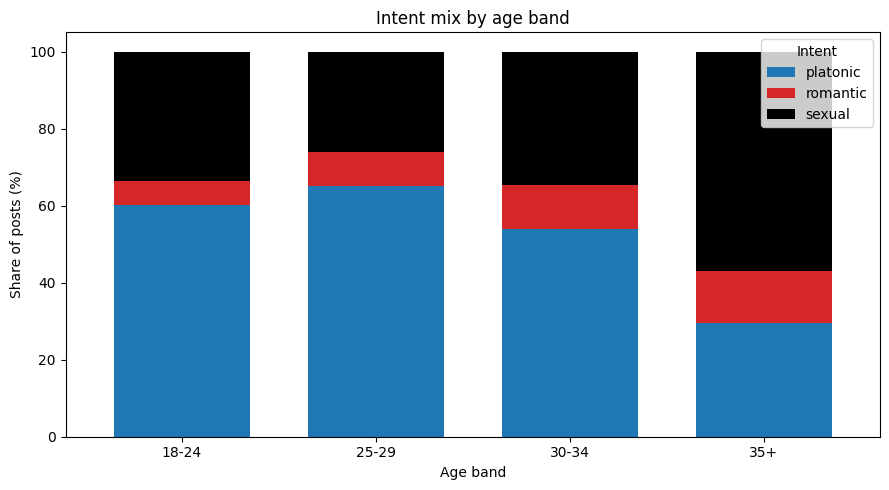

In [5]:
colors = {"platonic": "tab:blue", "romantic": "tab:red", "sexual": "black"}

ax = age_intent.mul(100).plot(
    kind="bar", stacked=True, figsize=(9, 5), width=0.7,
    color=[colors[c] for c in age_intent.columns],
)
ax.set_title("Intent mix by age band")
ax.set_xlabel("Age band")
ax.set_ylabel("Share of posts (%)")
ax.legend(title="Intent", loc="upper right")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig("../output/figures/fig7_age_intent.png", dpi=120)
plt.show()

## Monthly trend

A quick check that the late-night pattern is not just one busy month.

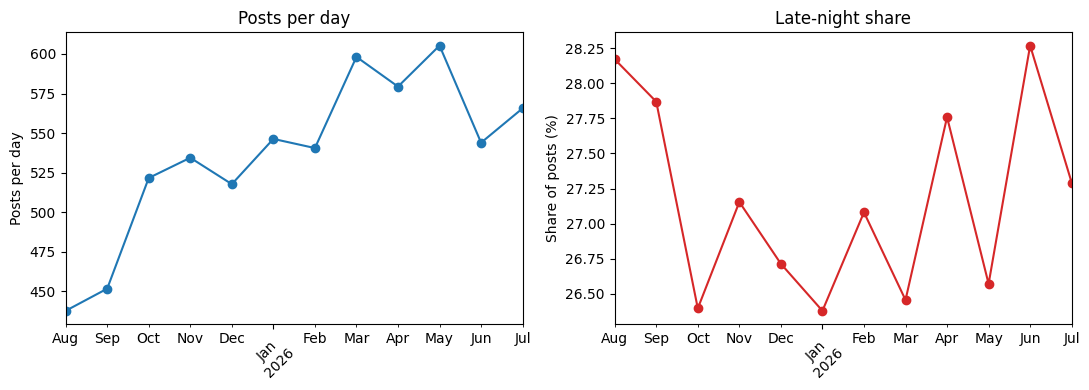

In [6]:
window["month_start"] = window["date_manila"].dt.to_period("M").dt.to_timestamp()
monthly = window.groupby("month_start").agg(
    posts=("post_id", "size"),
    late_night_share=("late_night", "mean"),
)
monthly = monthly[monthly.index < "2026-08-01"].copy()
monthly["posts_per_day"] = monthly["posts"] / monthly.index.days_in_month

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
monthly["posts_per_day"].plot(ax=axes[0], marker="o", color="tab:blue")
axes[0].set_title("Posts per day")
axes[0].set_xlabel("")
axes[0].set_ylabel("Posts per day")

monthly["late_night_share"].mul(100).plot(ax=axes[1], marker="o", color="tab:red")
axes[1].set_title("Late-night share")
axes[1].set_xlabel("")
axes[1].set_ylabel("Share of posts (%)")

for ax in axes:
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig("../output/figures/fig8_monthly_kpis.png", dpi=120)
plt.show()


Zooming in, it seems like late-night share % jump up and down every month but the percentage jumps are not that huge when zooming out of the data (e.g. Oct is below 26% vs Nov's 27%)

In [7]:
kpi.round(3).to_csv("../output/tables/m5_city_kpis.csv")
age_intent.round(3).to_csv("../output/tables/m5_age_intent.csv")
monthly.round(3).to_csv("../output/tables/m5_monthly.csv")
print("saved", len(kpi), "city rows and", len(monthly), "months")

saved 16 city rows and 12 months


## What the city filter leaves out

Only about 36% of posts name a city. Before using the city results, I check whether the posts that get left out look different.

In [8]:
window["has_city"] = window["city"].fillna("").ne("")
coverage = window.groupby("has_city").agg(
    posts=("post_id", "size"),
    late_night_share=("late_night", "mean"),
)
mix = pd.crosstab(window["has_city"], window["category"], normalize="index")
coverage = coverage.join(mix)
coverage.index = coverage.index.map({True: "City tagged", False: "No city"})
coverage.round(3)

,posts,late_night_share,all,platonic,romantic,sexual
has_city,,,,,,
No city,126652,0.294,0.510,0.343,0.038,0.109
City tagged,70430,0.230,0.607,0.138,0.043,0.211


Posts without a city are more late-night (29% vs 23%) and more platonic (34% vs 14%), so the city charts are not a full picture.


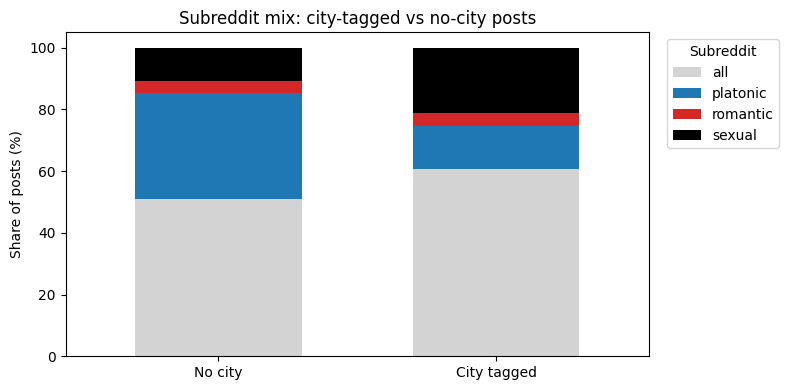

In [9]:
colors = {"all": "lightgray", "platonic": "tab:blue", "romantic": "tab:red", "sexual": "black"}
mix_plot = mix.rename(index={True: "City tagged", False: "No city"})
mix_plot = mix_plot[["all", "platonic", "romantic", "sexual"]]

ax = mix_plot.mul(100).plot(
    kind="bar", stacked=True, figsize=(8, 4), width=0.6,
    color=[colors[c] for c in mix_plot.columns],
)
ax.set_title("Subreddit mix: city-tagged vs no-city posts")
ax.set_xlabel("")
ax.set_ylabel("Share of posts (%)")
ax.legend(title="Subreddit", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig("../output/figures/fig9_city_coverage.png", dpi=120)
plt.show()

coverage.round(3).to_csv("../output/tables/m5_city_coverage.csv")

Posts without a city are not a random leftover. They are more late-night (29.4% vs 22.9%) and much more platonic (34.3% vs 13.8%). City-tagged posts are more general/sexual (60.7% general r4r and 21.1% sexual). So the city charts are a city-only view. They probably understate platonic demand and late-night posting.

## KPI definitions

| KPI | Calculation | Why it matters |
|---|---|---|
| Posts per 100,000 residents | all city posts / city population x 100,000 | compares overall demand across city sizes |
| Late-night share | posts between 10 PM and 2 AM / all posts in the city | shows when outreach or events should be active |
| Platonic posts per 100,000 | platonic-subreddit posts / city population x 100,000 | compares friendship demand across cities |
| Sexual posts per 100,000 | sexual-subreddit posts / city population x 100,000 | compares sexual-health demand across cities |

The city table also shows general r4r and romantic posts per 100,000. The four categories are subreddits, not a text-level intent classifier. "all" is a mixed bucket, so I compare each subreddit separately instead of pooling them into one intent share.


Each KPI answers a different question: reach, timing, friendship demand, and sexual-health demand.


## What this means

Makati has the highest per-capita volume by a wide margin: about 2,894 posts per 100,000 residents, compared with 746 in Manila and 593 in Quezon City. It also has the highest platonic (464) and sexual (400) posts per 100,000. Its late-night share is lower (19.6%), which is interesting given Makati's nightlife; maybe people there meet earlier, but the data cannot explain why. Sexual posts are only 13.8% of its total, so they are a smaller part of a very large overall market.

Pasay has the highest sexual share (36.1%) and a late-night share of 24.9%, but its sexual rate is 155 per 100,000, below Makati's 400. So Pasay is the most sexual-skewed city, not the biggest sexual market by population. Muntinlupa and Taguig have the highest platonic shares (18.5% and 16.9%), while Makati still has the highest platonic posts per 100,000.

Age shows a clear split in intent. Under-30 posters are mostly platonic (60% for 18-24 and 65% for 25-29), while 35+ is mostly sexual (57%). Late-night share stays between 26% and 28% across the 12 full months, so the timing KPI is stable. August 2026 is only three days, so I left it out of the trend.

## Limits

- Only about 36% of posts name a city.
- City matching keeps the first city mentioned when a post names more than one.
- Reddit posters are not a sample of city residents.
- These are descriptive rates, not evidence that one place causes a behavior.
- Small cities like San Juan (416 posts) and Malabon (67) have noisy per-capita rates.
